## Assignment 02: Fitting and Alignment

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A02.git

In [1]:
# libraries I used
import numpy as np
import matplotlib.pyplot as plt, glob, os
from PIL import Image
import cv2 as cv
from scipy.ndimage import maximum_filter

# Question 01


In [2]:
def drop_clusters(blobs):
    """
    I defined this function to drop clusters of blobs that are too close to each other."""
    out = []
    for b in blobs:
        n = sum(1 for o in blobs
                if o is not b and o[2] < b[2] and np.hypot(o[0]-b[0], o[1]-b[1]) < b[2])
                #it does this by checking if the distance between the two blobs is less than the radius of the bigger blob
        if n < 2:
            out.append(b)
    return out

sigma range: 10 - 40, number of scales: 50
Number of detected blobs: 34
largest 5 blobs (row, col, radius, sigma):
  (193, 185, 18.47, 13.06)
  (197, 45, 16.74, 11.84)
  (287, 64, 16.74, 11.84)
  (226, 359, 15.01, 10.61)
  (262, 276, 15.01, 10.61)


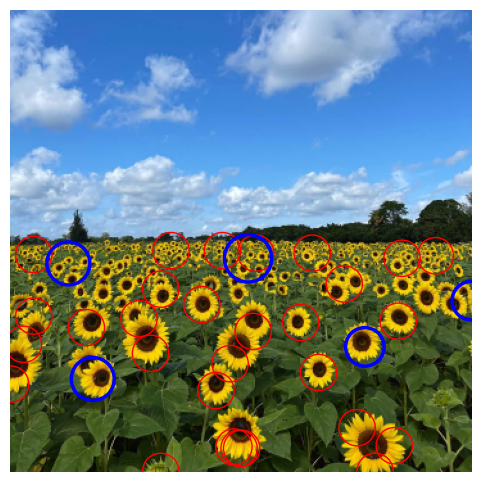

In [3]:
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
b, g, r = [im[:,:,k].astype(np.float32)/255 for k in range(3)]
gray = np.clip(r-b, 0, 1) # did this to enhance sunflowers in the image and surpress clouds


sigma_min = 10; sigma_max = 40; n_scales = 50; 
sigmas = np.linspace(sigma_min, sigma_max, n_scales)
stack = []

for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    stack.append((s**2) * cv.Laplacian(g, cv.CV_32F)) #since LoG is sigma^2 * Laplacian(Gaussian)

stack = np.stack(stack)
resp = -stack #as from before all dark blobs are now clouds due to plane substraction I chose bright blobs

thr = 0.25*resp.max()
nms = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp >= thr)
si, xs, ys = np.nonzero(nms)

blobs = [(xs_, ys_, np.sqrt(2)*sigmas[i], sigmas[i], resp[i, xs_, ys_])
         for i, xs_, ys_ in zip(si, xs, ys)]

blobs = drop_clusters(blobs)
blobs.sort(key=lambda b: -b[2])

print(f"sigma range: {sigma_min} - {sigma_max}, number of scales: {n_scales}")
print(f"Number of detected blobs: {len(blobs)}")
print("largest 5 blobs (row, col, radius, sigma):")
for x, y, r, s, _ in blobs[:5]:
    print(f"  ({x}, {y}, {r:.2f}, {s:.2f})")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for x, y, r, s, *_ in blobs:
    ax.add_patch(plt.Circle((y, x), r, color='red', fill=False, lw=1))

for x, y, r, s, *_ in blobs[:5]: #top 5
    ax.add_patch(plt.Circle((y, x), r, color='blue', fill=False, lw=2.5))

ax.axis('off'); plt.show()


### Intepretation and Disscussion

Substracting the blue from red made yellow petals bright and the sky and white clouds dark. Through that I was able to remove the false detections that was cluttering the output (I assumed the requirement to detect only sunflowers(petals + brown head) as blobs) when I used just the grayscale input.

We can clearly see that the flowers in the foreground are identified perfectly as blobs while the ones in the background are bunched up, this is because the high minimum sigma values which I had to use to select the brown heads of the flowers as well.

One limitaition is that several of the largest circles (blue) are not single flowers. They sit on groups of small, distant flowers that merge into one bright patch at larger $\sigma$, so LoG treats the group as one blob. But couple are still detecting a whole flowers which are in the foreground.


## Question 02


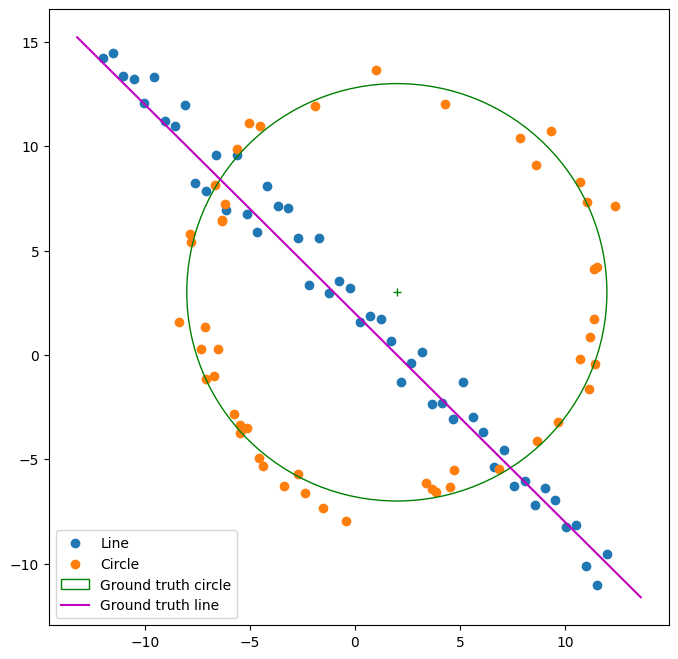

In [4]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt , y0_gt = 2 , 3 # Center
s = r /16
t = np . random . uniform (0 , 2*np . pi , half_n )
n = s*np . random . randn ( half_n )
x , y = x0_gt + ( r + n)*np . cos ( t ) , y0_gt + ( r + n)*np . sin ( t )
X_circ = np . hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
s = 1.
m, b = -1, 2
x = np . linspace (-12, 12 , half_n )
y = m*x + b + s*np . random . randn ( half_n )
X_line = np.hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
X = np.vstack ( ( X_circ , X_line ) ) # All points

fig , ax = plt.subplots (1 ,1 , figsize=(8 ,8))
ax.scatter ( X_line [ : , 0 ] , X_line [ : , 1 ] , label='Line' )
ax.scatter ( X_circ [ : , 0 ] , X_circ [ : , 1 ] , label='Circle' )
circle_gt = plt.Circle( ( x0_gt , y0_gt ) , r , color= 'g' , fill =False , label='Ground truth circle' )
ax.add_patch ( circle_gt )
ax.plot ( ( x0_gt ) , ( y0_gt ) , '+' , color= 'g' )
x_min , x_max = ax . get_xlim ( )
x_ = np . array ( [ x_min , x_max ] )
y_ = m*x_ + b
plt . plot ( x_ , y_ , color= 'm' , label= 'Ground truth line')
plt . legend ( )

In [5]:
#--(a)--
rng = np.random.default_rng(0)

def line_from_2pts(p,q):
    dv=p-q
    n=np.array([-dv[1],dv[0]])/ np.linalg.norm(dv)
    return n, np.dot(n,p)

def line_err(X,n,d):
    return np.abs(X @ n - d)

def fit_line_tls(P):
    c = P.mean(0)
    n=np.linalg.svd(P-c)[2][-1]
    return n, np.dot(n,c)

def ransac_line(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        i,j = rng.choice(len(X), size=2, replace=False)
        n,d = line_from_2pts(X[i],X[j])
        inl = line_err(X,n,d)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=(i,j), n=n, d=d)
    return best

t_line, min_line = 1.5, 35
L = ransac_line(X, t_line, min_line)
n_ref, d_ref = fit_line_tls(X[L['inl']])

print("best-sample line (a, b, d):", L['n'], L['d'])
print("refit line (a, b, d):", n_ref, d_ref, "| inliers:", L['inl'].sum())

best-sample line (a, b, d): [-0.73724186 -0.67562892] -1.0947426052823317
refit line (a, b, d): [0.72146373 0.69245223] 1.4541367601344581 | inliers: 56


#### Discussion

*Parameter choice.* Noise ($\sigma$ = 1) is added to the y coordinate of the line points, so the normal distance to the true line has $\sigma$ = 1/√2 ≈ 0.71. A threshold of 1.5 (about 2.1 $\sigma$) keeps about 96% of true line points, roughly 48 of 50, while rejecting most points that are not near the line. The minimum consensus was set to 35, safely below the expected count but far above what a random line through the circle points would collect. The number of iterations needed is N = log(1 − p) / log(1 − $w^s$ ). With an inlier ratio w ≈ 0.5, sample size s = 2 and p = 0.99, this gives N $\approx$ 17, so 500 iterations is more than enough.

*Result (seed 0 for both the data and RANSAC).* The best-sample line was n = [0.737, 0.676], d = 1.095 (sign flipped from the computed normal to compare with the refit). The TLS refit on its 56 inliers gave n = [0.721, 0.692], d = 1.454. The ground truth y = −x + 2 has n = [0.707, 0.707], d = 1.414. The refit is much closer, with a d error of 0.04 versus 0.32 and an angle error of about 1.2° versus 2.5°, because two noisy points give an unreliable line while TLS averages over all inliers. The 56 inliers exceed the 50 line points, so at least 6 circle points lie within the threshold where the circle crosses the line. They are removed before the circle fit.

In [6]:
#---(b)---
def circle_from_3pts(p1,p2,p3):
    A = 2* np.array([p2-p1, p3-p1])
    b_ = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-10:
        return None
    c = np.linalg.solve(A, b_)
    r = np.linalg.norm(c - p1)
    return c, r

def circle_err(X, c, r):
    return np.abs(np.linalg.norm(X - c, axis=1) - r)

def ransac_circle(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        idx = rng.choice(len(X), size=3, replace=False)
        out = circle_from_3pts(X[idx[0]], X[idx[1]], X[idx[2]])
        if out is None:
            continue
        c,r_  = out
        inl = circle_err(X,c,r_)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=idx, c=c, r=r_)
    return best

def fit_circle(P, c0, r0):
    f = lambda q: np.sum((np.linalg.norm(P-q[:2], axis=1)-q[2])**2)
    res = minimize(f, [*c0, r0])
    return res.x[:2], res.x[2]

X_rem = X[~L['inl']]
t_circ, min_circ = 1.25, 25
C = ransac_circle(X_rem, t_circ, min_circ)
c_ref, r_ref = fit_circle(X_rem[C['inl']], C['c'], C['r'])

print("remnant points:", len(X_rem))
print("best-sample circle (cx, cy, r):", C['c'], C['r'])
print("refit circle (cx, cy, r):", c_ref, r_ref, "| inliers:", C['inl'].sum())
print("ground truth: (2, 3), r = 10")

remnant points: 44
best-sample circle (cx, cy, r): [2.28594286 2.93239813] 9.982216129111203
refit circle (cx, cy, r): [1.88941921 3.02205753] 9.961816618172943 | inliers: 43
ground truth: (2, 3), r = 10


#### Discussion

*Parameter choice.* The radial noise is $\sigma$ = r/16 = 0.625, so a threshold of 1.25 (2 $\sigma$) keeps about 95% of true circle points. At most 50 circle points remain after the line inliers are removed, so a minimum consensus of 25 is well above chance and below the expected count. With w $\approx$ 0.8, s = 3 and p = 0.99, N = log(1 − p) / log(1 − $w^s$) $\approx$ 7, so 500 iterations is again more than enough.

*Result (seed 0 for both the data and RANSAC).* 44 points remained after the line inliers were removed. The best-sample circle was centre (2.29, 2.93), r = 9.98. The refit on its 43 inliers gave centre (1.89, 3.02), r = 9.96. The ground truth is centre (2, 3), r = 10. The refit centre error is 0.11 compared with 0.29 for the three-point circle, while both radii are within 0.04 of the true value. The refit is more reliable because it averages 43 points instead of depending on three noisy ones. Only one remnant point was rejected as an outlier, which fits the 2 $\sigma$ threshold (about 5% expected to be rejected).

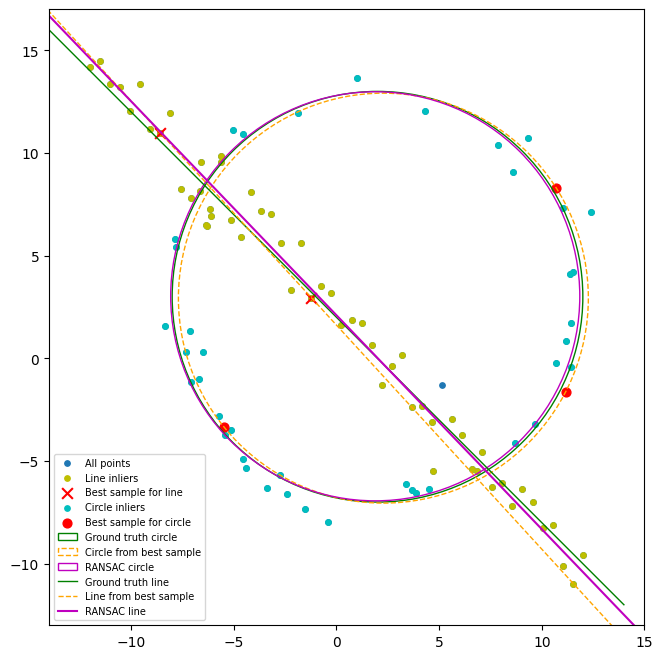

In [7]:
#---(c)---
def draw_line(ax, n, d, **kw):
    p0, dv = n * d, np.array([-n[1], n[0]])
    q = np.array([p0 - 25 * dv, p0 + 25 * dv])
    ax.plot(q[:, 0], q[:, 1], **kw)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', s=15, label='All points')
ax.scatter(*X[L['inl']].T, c='y', s=15, label='Line inliers')
ax.scatter(*X[list(L['sample'])].T, c='r', marker='x', s=60, label='Best sample for line')
ax.scatter(*X_rem[C['inl']].T, c='c', s=15, label='Circle inliers')
ax.scatter(*X_rem[C['sample']].T, c='r', s=40, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(C['c'], C['r'], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle(c_ref, r_ref, color='m', fill=False, label='RANSAC circle'))
xs_ = np.array([-14, 14])
ax.plot(xs_, m * xs_ + b, 'g', lw=1, label='Ground truth line')
draw_line(ax, L['n'], L['d'], color='orange', ls='--', lw=1, label='Line from best sample')
draw_line(ax, n_ref, d_ref, color='m', label='RANSAC line')
ax.set_xlim(-14, 15); ax.set_ylim(-13, 17)
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### (d) Fitting the circle first

Fitting the circle first is unreliable. A circle has three parameters and can approximate a line over a segment: three points taken from the line define a very large, nearly straight circle that passes through most of the line points. Its consensus can therefore be comparable to that of the true circle, so RANSAC may return this useless "circle". Even when the true circle wins, its consensus band also contains the line points that cross the circle, which pull the refit away from the true circle and are then removed from the line's data.

Fitting the line first is more robust. The line is the simpler model (two parameters, two-point samples), so a random sample is more likely to be all inliers, and the circle points curve away from the line so they do not form a competing consensus. After its inliers are removed, the remaining points are mostly circle points. In general, the most constrained model should be fitted first, and the more flexible one on the remnant.

## Question 03

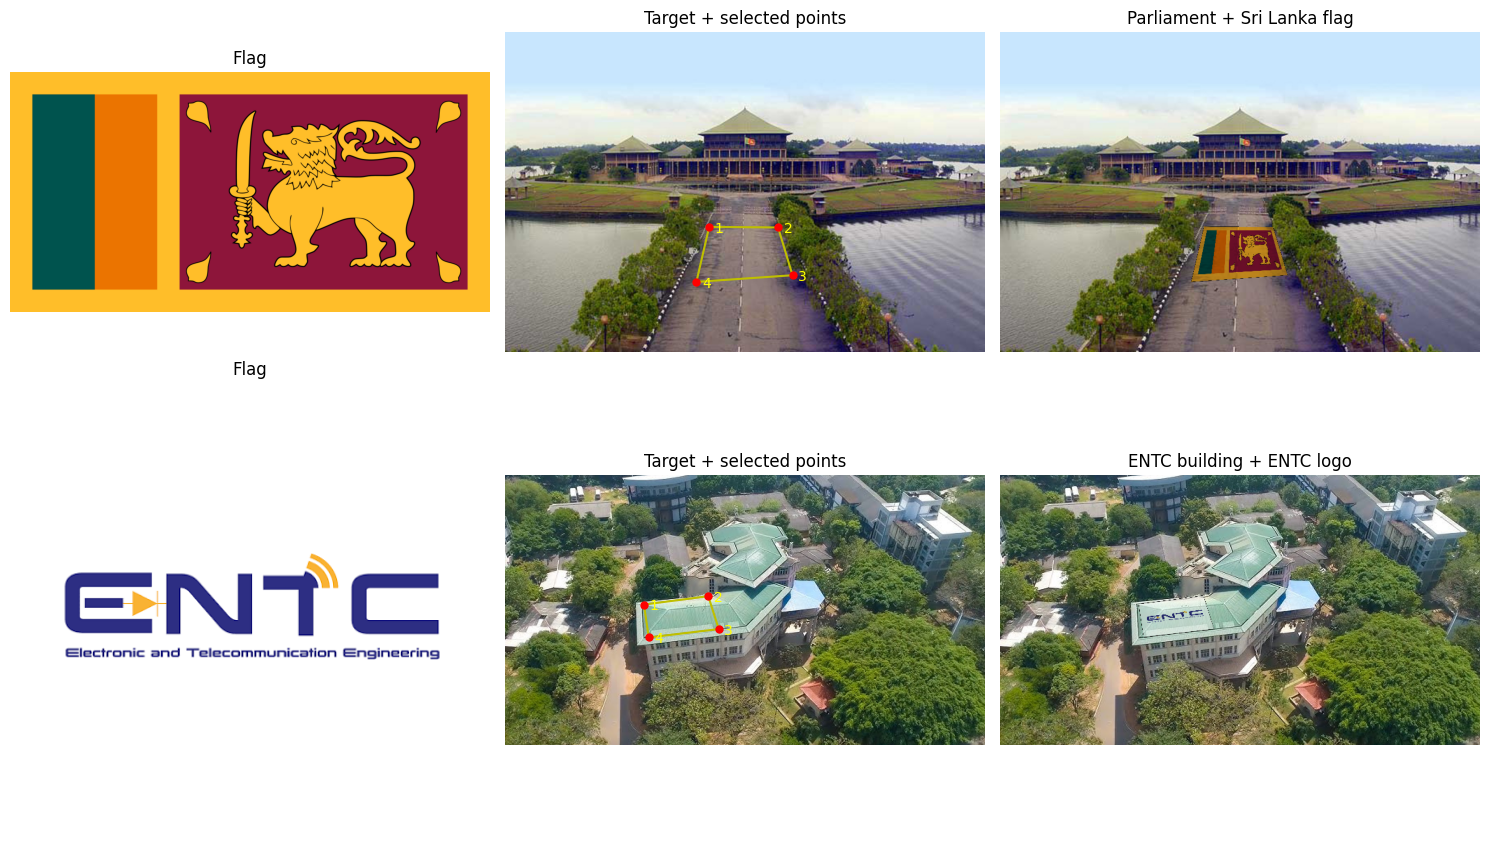

In [8]:
dst_pts=[]
CLICK_ORDER = ["TL", "TR", "BR", "BL"] # added to be consistant every time selecting


def select_points(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(dst_pts) < 4:
        dst_pts.append([x, y])
        cv.circle(param, (x,y), 6, (0,0,255), -1)
        cv.putText(param, f"{len(dst_pts)}:{CLICK_ORDER[len(dst_pts)-1]}", (x+8, y-8),
                   cv.FONT_HERSHEY_SIMPLEX, 1, (0,255,255),2) #to ensure correct order is clikced
        

def overlay_flag(target_path, flag_path, output_path):
    global dst_pts
    dst_pts = []

    target_img = cv.imread(target_path)
    flag_img = cv.imread(flag_path) 

    tem_img = target_img.copy()
    cv.namedWindow("Select 4 points on planar surface", cv.WINDOW_NORMAL)
    cv.setMouseCallback("Select 4 points on planar surface", select_points, tem_img)  

    while len(dst_pts) < 4:
        cv.imshow("Select 4 points on planar surface", tem_img)
        if cv.waitKey(20) & 0xFF == 27:  # Exit on ESC key
            break
    cv.destroyAllWindows()

    if len(dst_pts) < 4:
        print("Not enough points selected")
        return None

    h_flag, w_flag = flag_img.shape[:2]
    src_pts = np.float32([
        [0, 0], 
        [w_flag - 1, 0], 
        [w_flag - 1, h_flag - 1], 
        [0, h_flag - 1]
    ])

    dst_pts_np = np.float32(dst_pts)

    H, _ = cv.findHomography(src_pts, dst_pts_np)
    h_target, w_target = target_img.shape[:2]
    warped_flag = cv.warpPerspective(flag_img, H, (w_target, h_target))

    mask = np.zeros((h_target, w_target), dtype=np.uint8)
    cv.fillConvexPoly(mask, dst_pts_np.astype(int), 255)

    result = target_img.copy()

    bg_region = target_img[mask == 255].astype(float) / 255.0
    flag_region = warped_flag[mask == 255].astype(float) / 255.0

    multiply_layer = bg_region * flag_region
    blend_factor = 0.4  
    final_region = (blend_factor * flag_region + (1 - blend_factor) * multiply_layer) * 255.0

    result[mask == 255] = np.clip(final_region, 0, 255).astype(np.uint8)

    cv.imwrite(output_path, result)
    return target_img, flag_img, result, dst_pts_np      


pairs = [   # (target, flag, output, title)
    ('a2images\\parliment.jpg',     'a2images\\sri_lanka.webp', 'results\\q3_result_2.jpg', 'Parliament + Sri Lanka flag'),
    ('a2images\\entc_building.jpg', 'a2images\\entc.png',       'results\\q3_result_4.jpg', 'ENTC building + ENTC logo'),
    
]

fig, axes = plt.subplots(len(pairs), 3, figsize=(15, 4.5 * len(pairs)), squeeze=False)
for (t, f, o, title), ax in zip(pairs, axes):
    out = overlay_flag(t, f, o)
    for a in ax:
        a.axis('off')
    if out is None:
        continue
    target_img, flag_img, result, pts = out
    ax[0].imshow(cv.cvtColor(flag_img, cv.COLOR_BGR2RGB)); ax[0].set_title('Flag')
    ax[1].imshow(cv.cvtColor(target_img, cv.COLOR_BGR2RGB)); ax[1].set_title('Target + selected points')
    q = np.vstack([pts, pts[:1]])
    ax[1].plot(q[:, 0], q[:, 1], 'y-', lw=1.5)
    for k, (c_, r_) in enumerate(pts):
        ax[1].plot(c_, r_, 'ro', ms=5)
        ax[1].annotate(f"{k+1}", (c_, r_), color='yellow', xytext=(4, -4), textcoords='offset points')
    ax[2].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB)); ax[2].set_title(title)
plt.tight_layout()
plt.savefig('results\\q3_summary.png', dpi=150, bbox_inches='tight')
plt.show()


### Discussion

To place the flag, I click 4 corners on a flat surface in the target image in the order top-left, top-right, bottom-right, bottom-left, so they match the 4 corners of the flag image. With 4 point pairs there are 8 equations, which is enough to find the 8 unknowns of the homography $H$, so I used cv2.findHomography. Then cv2.warpPerspective warps the flag onto that area, and I used a mask of the selected area so only that part of the image gets changed.

For blending, just replacing the pixels with the flag looked flat and fake, like a sticker. Multiply blending ($I_{bg} \times I_{flag}$) keeps the wall texture and shadows, but white parts of the flag become invisible because multiplying by white does not change the background. So I mixed both as $0.4 \cdot I_{flag} + 0.6 \cdot I_{bg} I_{flag}$. This way the white parts still show and you can still see the texture of the building through the flag.

For the images, I put the Sri Lankan flag on the road to the Parliament building. I also put the ENTC logo on top od the ENTC building. I chose both because the surfaces there are flat, so a homography can map the flag onto them properly. On a curved or uneven surface it would not look right, since a homography only works for a plane.

## Question 04

AAAA1.jpg: good matches 39, RANSAC inliers 7  -> UNRELIABLE alignment


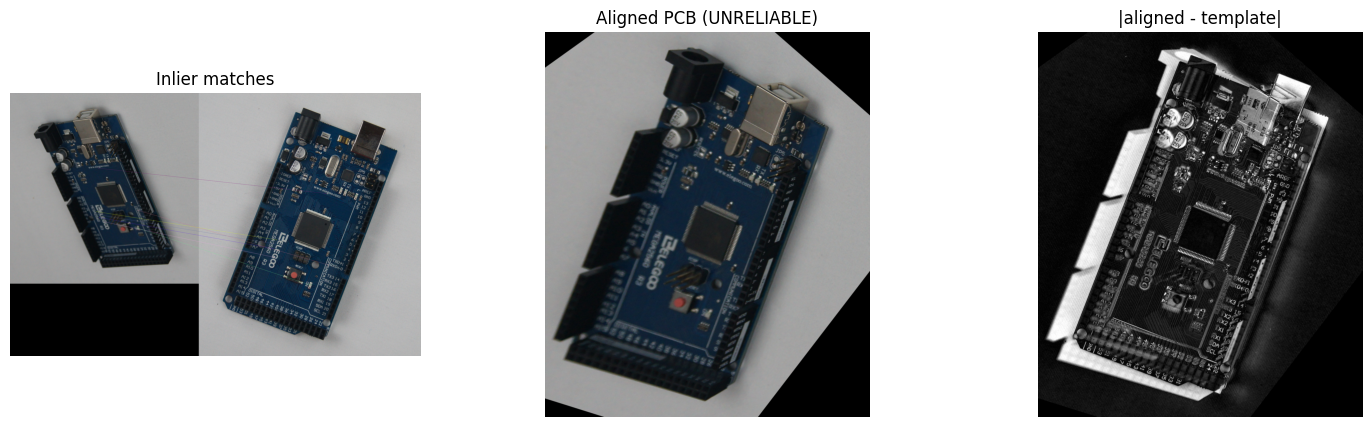

ADAD1.jpg: good matches 278, RANSAC inliers 157


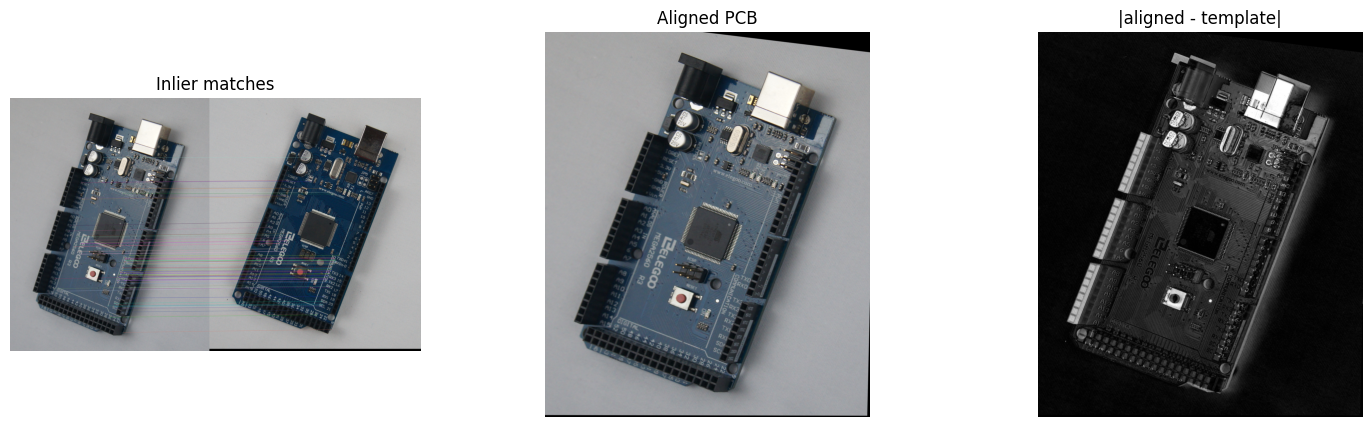

AECC2.jpg: good matches 4868, RANSAC inliers 4502


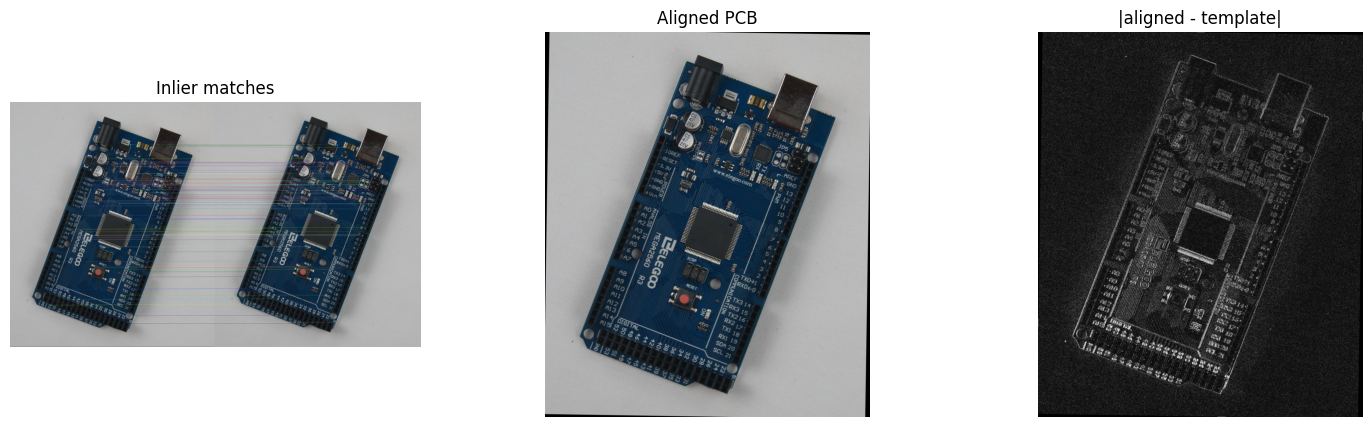

AECC3.jpg: good matches 6239, RANSAC inliers 5722


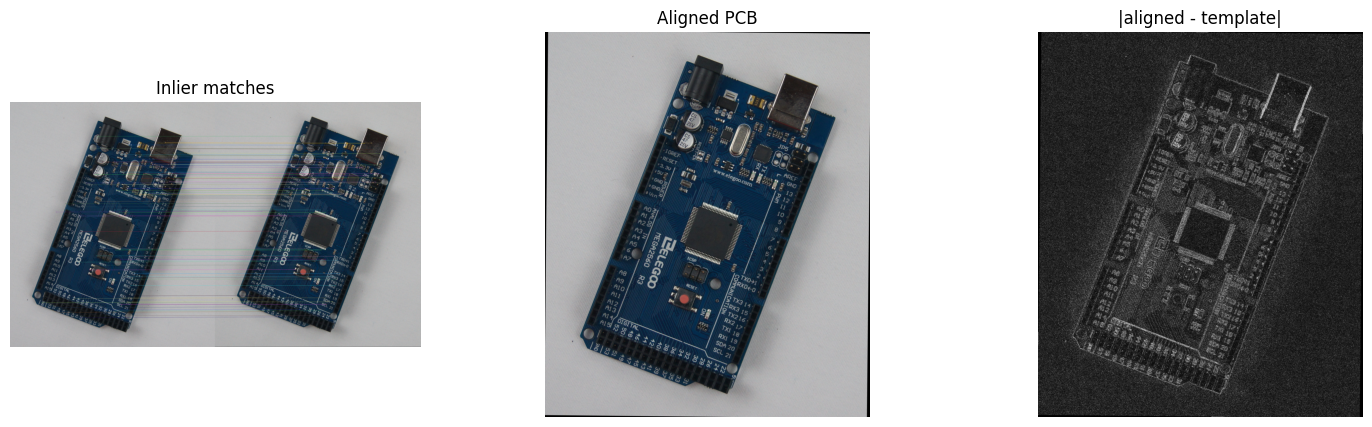

AECC4.jpg: good matches 4355, RANSAC inliers 3983


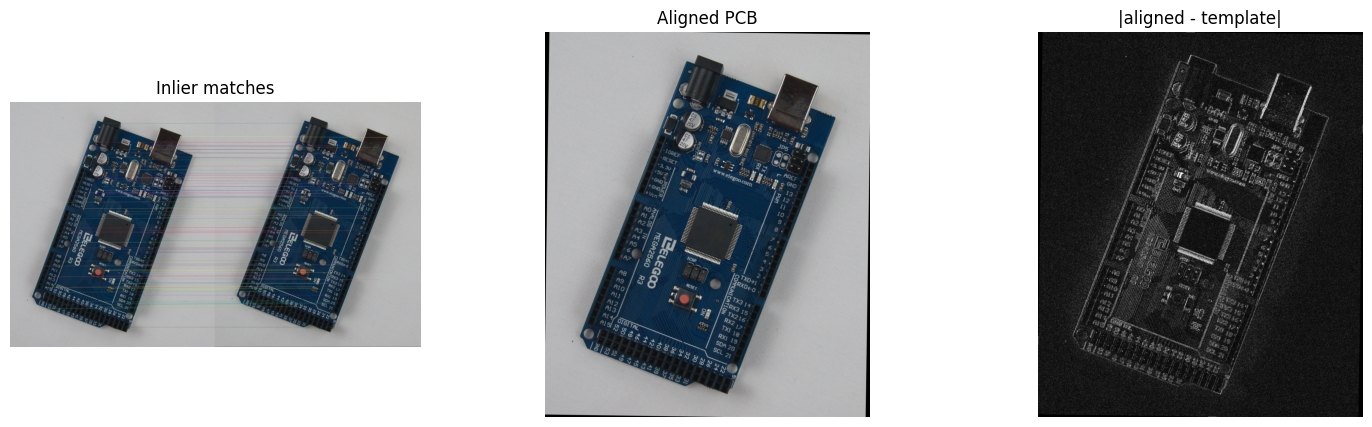


image        good  inliers  ratio  ok
AAAA1.jpg      39        7   0.18  False
ADAD1.jpg     278      157   0.56  True
AECC2.jpg    4868     4502   0.92  True
AECC3.jpg    6239     5722   0.92  True
AECC4.jpg    4355     3983   0.91  True


In [9]:
tmpl = cv.imread('a2images\\pcbs\\AECC1.jpg')
tmpl_g = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY)
h_tmpl, w_tmpl = tmpl_g.shape


clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)) #as some imgs were too dark and didn't gave points
sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(clahe.apply(tmpl_g), None)          # (a) template features  
bf = cv.BFMatcher()
rng_vis = np.random.default_rng(0) #for consistancy on future runs and discussion
summary=[]

for path in sorted(glob.glob('a2images\\pcbs\\*.jpg')):
    if os.path.basename(path) == 'AECC1.jpg':
        continue
    img = cv.imread(path)
    img_g = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp_i, des_i = sift.detectAndCompute(clahe.apply(img_g), None)       # (a) PCB features   

    knn = bf.knnMatch(des_i, des_t, k=2)
    good_matches = [pr[0] for pr in knn if len(pr) == 2 and pr[0].distance < 0.75 * pr[1].distance]   

    best = {}                                             
    for mt in good_matches:
        if mt.trainIdx not in best or mt.distance < best[mt.trainIdx].distance:
            best[mt.trainIdx] = mt
    good_matches = list(best.values())

    if len(good_matches) <= 10:                                                         
        print(f"Not enough matches found in {os.path.basename(path)}: {len(good_matches)}")
        continue

    src = np.float32([kp_i[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)   # PCB
    dst = np.float32([kp_t[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)   # template
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)                              # PCB -> template   
    if H is None:
        print(f"Homography failed for {os.path.basename(path)}")
        continue

    inl = mask.ravel().astype(bool)
    ok = inl.sum() >=50 and inl.mean() >= 0.3
    summary.append((os.path.basename(path), len(good_matches), int(inl.sum()), inl.mean(), ok))

    inl_matches = [m for m, k in zip(good_matches, inl) if k]
    idx = rng_vis.choice(len(inl_matches), min(80, len(inl_matches)), replace=False)
    vis = cv.drawMatches(img, kp_i, tmpl, kp_t, [inl_matches[i] for i in idx], None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # (c) align PCB to the template and take the difference
    warped = cv.warpPerspective(img, H, (w_tmpl, h_tmpl))

    valid = cv.warpPerspective(np.full(img_g.shape, 255, np.uint8), H, (w_tmpl, h_tmpl))
    valid = cv.erode(valid, np.ones((5, 5), np.uint8)) > 0
    wg = cv.cvtColor(warped, cv.COLOR_BGR2GRAY).astype(np.float32)
    tg = tmpl_g.astype(np.float32)
    wg = (wg - wg[valid].mean()) / wg[valid].std() * tg[valid].std() + tg[valid].mean()
    diff = np.abs(wg - tg)
    diff[~valid] = 0
    vmax = np.percentile(diff[valid], 99.5)

    print(f"{os.path.basename(path)}: good matches {len(good_matches)}, RANSAC inliers {inl.sum()}"
          + ("" if ok else "  -> UNRELIABLE alignment"))                               
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB));    ax[0].set_title('Inlier matches')
    ax[1].imshow(cv.cvtColor(warped, cv.COLOR_BGR2RGB)); ax[1].set_title('Aligned PCB' + ('' if ok else ' (UNRELIABLE)'))   
    ax[2].imshow(diff, cmap='gray', vmin=0, vmax=vmax);  ax[2].set_title('|aligned - template|')                            
    for a in ax: a.axis('off')
    plt.show()


print(f"\n{'image':10s} {'good':>6s} {'inliers':>8s} {'ratio':>6s}  ok")
for nm, g_, i_, rt, ok in summary:
    print(f"{nm:10s} {g_:6d} {i_:8d} {rt:6.2f}  {ok}")

### Discussion

I used SIFT to find features in the template (AECC1) and each PCB, and matched them with BFMatcher and the ratio test (0.75). Some boards were too dark and didn't give many points, so I used CLAHE first to improve the contrast. Then I found the homography with RANSAC and warped each PCB onto the template and took the difference.

My first difference images were almost all black. This was because the area outside the warped board is black, so the difference there was very high and the display got scaled to that. So I masked that area out, matched the brightness of the warped image to the template and limited the colour range. I also drew only 80 random matches because with thousands of lines we can't see anything.

The AECC boards aligned very well, over 90% of the matches were inliers and the difference is almost zero on most of the board. ADAD1 also aligned but with a lot less matches, I think because the lighting and angle are more different from the template.

AAAA1 did not work. Only 7 matches agreed on the homography so the result is wrong and I did not use it. The board is small in that photo and dark, so SIFT could not find enough matching points.

In the aligned boards the differences that are left are mostly around the USB port, the capacitors and the reset button.

**(e)** A homography only works for points on one flat plane. The board is flat so it lines up well, but the USB port, capacitors and reset button are tall and stick out. When the camera angle changes they move differently from the board, so the homography can't line them up and they show up in the difference image. The shiny metal parts and shadows also make the difference bigger.